# SnapKV Token Dropping Example with LMCache SDK
---

Long prompts create large KV caches that eat up GPU memory and limit how many 
requests fit in a batch, and a smaller batch means lower decode throughput. 
Token dropping shrinks each request's KV cache (in this example by half), so more
requests fits in a batch. This notebook shows improvement in decode 
throughput by 1.5-1.7x by using LMCache's SDK API that enables ML engineers get
a requests' KV, do optimizations such as token dropping, and put it back to use
during LLM serving.

Additionally, this example proves that the accuracy of generation is unaffected,
even improved, by token dropping.

Requirements:
* A small 10-lines modification is needed on vLLM's side to expose intermediate
  tensors to LMCache. Please do the setup steps outlined in 
  [README.md](./README.md)
* This experiment requires a GPU. To demonstrate how token dropping increases 
  the decoding batch size, adjust the GPU memory utilization together with the 
  number of requests. This example uses one RTX 6000 PRO.
* This example uses shared memory for data transfer between LMCache server and
  the SDK. If shared memory is unavailable, the SDK automatically falls back to pickle.

## Setup vLLM and LMCache server
Follow below instructions (1-4), then proceed to below Python cell.

**1. Start LMCache server first**

To use shared memory, specify the `--shm-name` and `--no-l1-use-lazy`
To enable query tensor transfer, we load the qstore server module with `--server-module '{"module_path": "lmcache.v1.multiprocess.plugin_modules.qstore"}'`.

```sh
lmcache server \
    --l1-size-gb 210 \
    --eviction-policy LRU \
    --chunk-size 256 \
    --port 6555 \
    --http-port 8080 \
    --no-l1-use-lazy \
    --server-module '{"module_path": "lmcache.v1.multiprocess.plugin_modules.qstore"}' \
    --eviction-trigger-watermark 0.95 \
    --supported-transfer-mode lmcache_driven
```

**2. Wait until LMCache server is ready**

```sh
curl -sf http://localhost:8080/healthcheck && echo " LMCache ready"
```

**3. Start vLLM once LMCache server is ready**

We pass --no-enable-prefix-caching to disable vLLM's built-in prefix caching. 
This ensures the prefilled KV cache is always served from LMCache rather than 
vLLM, so the decoding throughput improvement can be attributed entirely to the 
tokens dropped through LMCache.

```sh
VLLM_SERVER_DEV_MODE=1 vllm serve Qwen/Qwen3-8B \
    --port 8000 \
    --served-model-name Qwen/Qwen3-8B \
    --no-enable-prefix-caching \
    --enforce-eager \
    --gpu-memory-utilization 0.49 \
    --no-enable-chunked-prefill \
    --max-model-len 24576 \
    --max-num-batched-tokens 24576 \
    --kv-transfer-config '{"kv_connector":"LMCacheMPConnector","kv_role":"kv_both","kv_connector_extra_config":{"lmcache.mp.port":6555,"lmcache.mp.transfer_intermediate_tensors":true,"lmcache.mp.q.ring_depth":5}}' \
    --trust-remote-code \
    --return-tokens-as-token-ids
```

To enable query tensor transfer, pass 
`"lmcache.mp.transfer_intermediate_tensors":true` as an additional argument
to `--kv-transfer-config`. To adjust the QRingBuffer capacity, which holds
the query tensor temporarily before storing in L1, pass `"lmcache.mp.q.ring_depth"`
which defaults to 2 (2 means the QRingBuffer can hold the query tensors of 2
forward passes).

**4. Wait until vLLM is ready**

```sh
curl -sf http://localhost:8000/v1/models && echo " vLLM ready"
```

In [ ]:
# SPDX-License-Identifier: Apache-2.0
"""End-to-end KV cache remapping driver for the SDK example."""

# Standard
from datasets import load_dataset
import math
import matplotlib.pyplot as plt
import sys
from transformers import AutoTokenizer, AutoConfig

# Third Party
import torch
import torch.nn.functional as F

# First Party
from lmcache.logging import init_logger
import lmcache.sdk as lmc_sdk
from lmcache.banner import print_banner_once
from utils import (
    rerotate_k_cache,
    make_post_completion,
    score_answers,
)

print_banner_once(sys.stdout)
logger = init_logger(__name__)

/home/rani/vllm/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[2026-11-05 13:20:20,252] LMCache INFO: torch_dev=<module 'torch.cuda' from '/home/rani/vllm/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py'>, torch_device_type=cuda (_device_detect.py:311:lmcache.v1.platform._device_detect)
[2026-11-05 13:20:20,254] LMCache INFO: Auto-selected backend [cuda] for accelerator 'cuda' from candidate backends [cuda, rocm]. (__init__.py:160:lmcache.v1.platform)



 _     __  __    ____           _          
| |   |  \/  |  / ___|__ _  ___| |__   ___      LMCache v0.5.7rc4.dev28 (g6e677526)
| |   | |\/| | | |   / _` |/ __| '_ \ / _ \     Website:  https://lmcache.ai/
| |___| |  | | | |__| (_| | (__| | | |  __/     Recipes:  https://docs.lmcache.ai/recipes
|_____|_|  |_|  \____\__,_|\___|_| |_|\___|     LinkedIn: https://www.linkedin.com/company/lmcache-lab
Set LMCACHE_DISABLE_BANNER=1 to hide this banner.



## Setting up hyperparameters

In [2]:
model_name = "Qwen/Qwen3-8B"
vllm_url = "http://localhost:8000"
lmcache_url = "http://localhost:8080"
lmcache_mq_url = "tcp://localhost:6555"
chunk_size = 256
max_tokens = 2048
temperature = 0.0  # greedy decode so generated answers are deterministic and scorable
timeout = 60  # timeout for context retrieval (seconds)
trust_remote_code = True

## Configuring the model and LMCache endpoint

In [21]:
tokenizer = AutoTokenizer.from_pretrained(
    model_name, trust_remote_code=trust_remote_code
)
config = AutoConfig.from_pretrained(model_name, trust_remote_code=trust_remote_code)
head_size = getattr(
    config, "head_dim", config.hidden_size // config.num_attention_heads
)
work_device = torch.device("cpu")
post_completion = make_post_completion(vllm_url, model_name, timeout)
ctx = lmc_sdk.kvcache.connect(
    url=lmcache_mq_url,
    http_url=lmcache_url,
    model_name=model_name,
    timeout=timeout,
)
qctx = lmc_sdk.qcache.connect(
    url=lmcache_mq_url,
    http_url=lmcache_url,
    model_name=model_name,
    timeout=timeout,
)

[2026-11-05 14:25:10,529] LMCache INFO: Initialized LMCacheSDKContext with instance_id=990357965582167753, model_name=Qwen/Qwen3-8B, chunk_size=256, kind=LMCacheSDKCacheKind.KV (context.py:125:lmcache.sdk.context)
[2026-11-05 14:25:10,535] LMCache INFO: Opened 1 Q ring(s) for Qwen/Qwen3-8B##query: 36 layers x [7680, 16, 4096], instances [2243222170635844097] (ring_mapping.py:207:lmcache.sdk.wrapper.ring_mapping)
[2026-11-05 14:25:10,536] LMCache INFO: Transferring Qwen/Qwen3-8B through vLLM's Q ring on cuda:0: 37748736 bytes per chunk object (context.py:284:lmcache.sdk.context)
[2026-11-05 14:25:10,546] LMCache INFO: Initialized LMCacheSDKContext with instance_id=4094215283623781326, model_name=Qwen/Qwen3-8B##query, chunk_size=256, kind=LMCacheSDKCacheKind.QUERY (context.py:125:lmcache.sdk.context)
[2026-11-05 14:25:10,551] LMCache INFO: Opened 1 Q ring(s) for Qwen/Qwen3-8B##query: 36 layers x [7680, 16, 4096], instances [2243222170635844097] (ring_mapping.py:207:lmcache.sdk.wrapper.ri

## Constructing Prompt

In [4]:
prompts = []
answers = []
ds = load_dataset("raniayu/token-dropping-demo", split="train")
for i, example in enumerate(ds):
    prompt = tokenizer.encode(ds[i]["prompt"], return_tensors="pt").squeeze(0).tolist()
    prompts.append(prompt)
    answers.append(ds[i]["answer"])

print(f"Loaded {len(prompts)} prompts from the dataset.")
print(f"Total prompts length: {sum(len(p) for p in prompts)} tokens.")
print(f"Mean prompt length: {sum(len(p) for p in prompts) / len(prompts):.2f} tokens.")
print(f"Max prompt length: {max(len(p) for p in prompts)} tokens.")
print(f"Min prompt length: {min(len(p) for p in prompts)} tokens.")

Loaded 30 prompts from the dataset.
Total prompts length: 423428 tokens.
Mean prompt length: 14114.27 tokens.
Max prompt length: 16807 tokens.
Min prompt length: 10159 tokens.


## Baseline (without token dropping)

In [24]:
batch = lmc_sdk.batch.LMCacheBatchedStream()
for i, prompt in enumerate(prompts):
    request = lmc_sdk.request.create_request(
        contexts=[ctx, qctx],
        post_completion=post_completion,
        prompt_token_ids=prompt,
    )
    batch.add(request)
results = batch.prefill(
    sampling_params={"max_tokens": 1, "temperature": 1.0, "ignore_eos": True}
)
results.emit()

logger.info("\n\n")

results = batch.decode(
    sampling_params={
        "max_tokens": max_tokens,
        "temperature": temperature,
        "ignore_eos": True,
    }
)
results.emit()
before_drop_data = results.to_dict()
before_texts = [request.output_text for request in batch.request_streams.values()]

[2026-11-05 14:41:30,425] LMCache INFO: 

 (3070514329.py:14:__main__)


======================= Batched Stream Metrics (prefill) =======================
-------------------------------- Configuration ---------------------------------
Number of Request Streams:                                                    30
----------------------------------- Results ------------------------------------
Total Duration (s):                                                        13.98
Total Input Tokens:                                                       423428
Input Throughput (tokens/s):                                            30284.05
======================= Batched Stream Metrics (decode) ========================
-------------------------------- Configuration ---------------------------------
Number of Request Streams:                                                    30
----------------------------------- Results ------------------------------------
Total Duration (s):                                                        64.14
Total Output Tokens:        

## Clear LMCache

In [23]:
!curl -X POST {lmcache_url}/cache/clear -H "Content-Type: application/json" -d '{{"tier": "l1", "force": true}}'
!curl -X POST {vllm_url}/reset_prefix_cache

{"status":"ok","cleared":{"tier":"l1"}}

## With Token Dropping

In [7]:
CUDA_VISIBLE_DEVICES = "0"

snapkv_window_size = 64
snapkv_drop_ratio = 0.5
snapkv_kernel_size = 5
snapkv_pooling = "avgpool"


def _normalize_q_tensor(q_tensor: torch.Tensor) -> torch.Tensor:
    """Return q as [num_layers, T, num_q_heads * head_size]."""
    if q_tensor.ndim == 4:
        if q_tensor.shape[0] != 1:
            raise ValueError(f"expected q_tensor first dim 1, got {q_tensor.shape}")
        return q_tensor[0]
    if q_tensor.ndim == 3:
        return q_tensor
    raise ValueError(f"expected q_tensor 3D or 4D, got {q_tensor.shape}")


def _snapkv_layer_scores(
    k_flat: torch.Tensor,
    q_flat: torch.Tensor,
    *,
    seq_len: int,
    window_size: int,
    kernel_size: int,
    pooling: str,
    num_kv_heads: int,
    num_q_heads: int,
    head_size: int,
    device: torch.device,
) -> torch.Tensor:
    """Return one importance score per non-window past token."""
    if num_q_heads % num_kv_heads != 0:
        raise ValueError(
            f"num_q_heads ({num_q_heads}) must be divisible by "
            f"num_kv_heads ({num_kv_heads})"
        )

    groups = num_q_heads // num_kv_heads
    past_len = seq_len - window_size

    k = k_flat[:seq_len].to(device=device, dtype=torch.float32)
    q = q_flat[:seq_len].to(device=device, dtype=torch.float32)

    k = k.reshape(seq_len, num_kv_heads, head_size).permute(1, 0, 2)
    q = q.reshape(seq_len, num_q_heads, head_size)
    q = q.reshape(seq_len, num_kv_heads, groups, head_size)
    q_recent = q[-window_size:].permute(1, 2, 0, 3)

    attn = torch.einsum("kgwd,ktd->kgwt", q_recent, k) / math.sqrt(head_size)

    causal = torch.triu(
        torch.full(
            (window_size, window_size),
            torch.finfo(attn.dtype).min,
            dtype=attn.dtype,
            device=device,
        ),
        diagonal=1,
    )
    attn[..., -window_size:] += causal

    attn = F.softmax(attn, dim=-1, dtype=torch.float32)
    past_scores = attn[..., :past_len].sum(dim=-2)

    channels = past_scores.reshape(1, -1, past_len)
    if pooling == "avgpool":
        channels = F.avg_pool1d(
            channels, kernel_size=kernel_size, padding=kernel_size // 2, stride=1
        )
    elif pooling == "maxpool":
        channels = F.max_pool1d(
            channels, kernel_size=kernel_size, padding=kernel_size // 2, stride=1
        )
    else:
        raise ValueError(f"Pooling method not supported: {pooling}")

    return channels[..., :past_len].reshape(-1, past_len).mean(dim=0)


def drop_tokens_fn(
    tensors: dict[lmc_sdk.context.LMCacheSDKCacheKind, torch.Tensor],
    token_source: list[int],
) -> tuple[torch.Tensor, list[int]]:
    """SnapKV token dropping: keep top-scored past tokens plus the last window."""
    q_tensor = tensors[lmc_sdk.context.LMCacheSDKCacheKind.QUERY]
    kv_tensor = tensors[lmc_sdk.context.LMCacheSDKCacheKind.KV]

    q_by_layer = _normalize_q_tensor(q_tensor)

    seq_len = min(kv_tensor.shape[2], q_by_layer.shape[1], len(token_source))

    num_q_heads = config.num_attention_heads
    num_kv_heads = getattr(config, "num_key_value_heads", num_q_heads)
    head_dim = getattr(config, "head_dim", config.hidden_size // num_q_heads)

    if kv_tensor.shape[-1] != num_kv_heads * head_dim:
        raise ValueError(
            f"KV hidden dim {kv_tensor.shape[-1]} != {num_kv_heads * head_dim}"
        )
    if q_by_layer.shape[-1] != num_q_heads * head_dim:
        raise ValueError(
            f"Q hidden dim {q_by_layer.shape[-1]} != {num_q_heads * head_dim}"
        )

    past_len = seq_len - snapkv_window_size
    if past_len <= 0:
        raise ValueError(
            f"seq_len ({seq_len}) must exceed window ({snapkv_window_size})"
        )

    # Total tokens to retain, including recent window here
    total_keep = int(round(seq_len * (1 - snapkv_drop_ratio)))
    keep_past = max(0, min(total_keep - snapkv_window_size, past_len))

    scores = torch.zeros(past_len, dtype=torch.float32, device=work_device)
    for layer in range(kv_tensor.shape[1]):
        scores += _snapkv_layer_scores(
            kv_tensor[0, layer],
            q_by_layer[layer],
            seq_len=seq_len,
            window_size=snapkv_window_size,
            kernel_size=snapkv_kernel_size,
            pooling=snapkv_pooling,
            num_kv_heads=num_kv_heads,
            num_q_heads=num_q_heads,
            head_size=head_dim,
            device=work_device,
        )
    scores /= kv_tensor.shape[1]

    past_keep = torch.topk(scores, k=keep_past, largest=True).indices.sort().values
    last_window = torch.arange(past_len, seq_len, device=work_device)
    keep_idx = torch.cat([past_keep, last_window]).to(dtype=torch.long)
    # keep_idx = torch.arange(seq_len, device=work_device)

    keep_idx_cpu = keep_idx.cpu()
    kept_ids = [token_source[i] for i in keep_idx_cpu.tolist()]

    e_kv = rerotate_k_cache(
        kv_tensor[:, :, keep_idx_cpu, :].clone().to(work_device),
        old_positions=keep_idx,
        new_positions=torch.arange(keep_idx.numel(), device=work_device),
        model_config=config,
    )

    logger.info("compacted %s/%s tokens.", e_kv.shape[2], kv_tensor.shape[2])

    return e_kv.cpu(), kept_ids

In [ ]:
stream_ids = []

batch = lmc_sdk.batch.LMCacheBatchedStream()
for i, prompt in enumerate(prompts):
    request = lmc_sdk.request.create_request(
        contexts=[ctx, qctx],
        post_completion=post_completion,
        prompt_token_ids=prompt,
    )
    batch.add(request)
    stream_ids.append(request.request_stream_id)

results = batch.prefill(
    sampling_params={"max_tokens": 1, "temperature": 1.0, "ignore_eos": True}
)
results.emit()

logger.info("\n\n")

results = batch.modify(drop_tokens_fn)
results.emit()

logger.info("\n\n")

results = batch.decode(
    sampling_params={
        "max_tokens": max_tokens,
        "temperature": temperature,
        "ignore_eos": True,
    }
)
results.emit()
after_drop_data = results.to_dict()
after_texts = [request.output_text for request in batch.request_streams.values()]

[2026-11-05 14:25:31,524] LMCache INFO: 

 (2243057919.py:18:__main__)


======================= Batched Stream Metrics (prefill) =======================
-------------------------------- Configuration ---------------------------------
Number of Request Streams:                                                    30
----------------------------------- Results ------------------------------------
Total Duration (s):                                                        14.14
Total Input Tokens:                                                       423428
Input Throughput (tokens/s):                                            29938.47


[2026-11-05 14:27:01,277] LMCache INFO: compacted 5120/10240 tokens. (515457958.py:148:__main__)
[2026-11-05 14:27:09,267] LMCache INFO: compacted 4992/9984 tokens. (515457958.py:148:__main__)
[2026-11-05 14:27:16,003] LMCache INFO: compacted 5376/10752 tokens. (515457958.py:148:__main__)
[2026-11-05 14:27:23,793] LMCache INFO: compacted 5376/10752 tokens. (515457958.py:148:__main__)
[2026-11-05 14:27:34,004] LMCache INFO: compacted 5632/11264 tokens. (515457958.py:148:__main__)
[2026-11-05 14:27:37,443] LMCache INFO: compacted 5504/11008 tokens. (515457958.py:148:__main__)
[2026-11-05 14:27:44,728] LMCache INFO: compacted 5632/11264 tokens. (515457958.py:148:__main__)
[2026-11-05 14:27:55,571] LMCache INFO: compacted 6272/12544 tokens. (515457958.py:148:__main__)
[2026-11-05 14:28:00,464] LMCache INFO: compacted 6400/12800 tokens. (515457958.py:148:__main__)
[2026-11-05 14:28:08,758] LMCache INFO: compacted 6656/13312 tokens. (515457958.py:148:__main__)
[2026-11-05 14:28:16,086] LMCac

======================== Batched Stream Modify Metrics =========================
----------------------------------- Results ------------------------------------
Total Duration (s):                                                       380.66


[2026-11-05 14:32:19,239] LMCache INFO: 

 (2243057919.py:28:__main__)


gc took 26.5s
======================= Batched Stream Metrics (decode) ========================
-------------------------------- Configuration ---------------------------------
Number of Request Streams:                                                    30
----------------------------------- Results ------------------------------------
Total Duration (s):                                                        34.71
Total Output Tokens:                                                       61260
Decode Throughput (tokens/s):                                            1764.80


### Accuracy

In [25]:
before_correct, total, before_map = score_answers(answers, before_texts)
after_correct, total, after_map = score_answers(answers, after_texts)
logger.info(
    "Baseline (no drop): %s/%s correct (%.1f%%)",
    before_correct,
    total,
    100 * before_correct / total,
)
logger.info(
    "Token dropping: %s/%s correct (%.1f%%)",
    after_correct,
    total,
    100 * after_correct / total,
)

[2026-11-05 14:44:25,717] LMCache INFO: Baseline (no drop): 11/30 correct (36.7%) (234422767.py:3:__main__)
[2026-11-05 14:44:25,719] LMCache INFO: Token dropping: 9/30 correct (30.0%) (234422767.py:9:__main__)


## Result Plot

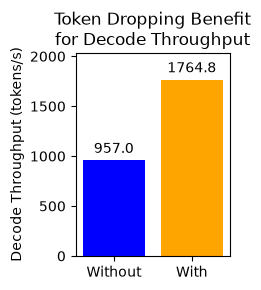

In [26]:
labels = ["Without", "With"]
data = [
    before_drop_data["metrics"]["results"]["output_tput"],
    after_drop_data["metrics"]["results"]["output_tput"],
]

fig, ax = plt.subplots(figsize=(2.5, 3))
bars = ax.bar(labels, data, color=["blue", "orange"])
ax.bar_label(bars, fmt="%.1f", padding=3)
ax.set_ylabel("Decode Throughput (tokens/s)")
ax.set_title("Token Dropping Benefit\nfor Decode Throughput")
ax.margins(y=0.15)
plt.tight_layout()
plt.show()

## Close both contexts

In [27]:
# Only close the context when done.
ctx.close()
qctx.close()